In [1]:
import os
import sys

root_dir = os.path.abspath("..")
if root_dir not in sys.path:
    sys.path.append(root_dir)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from model.model import EcoModel
from model.accounts import REAL_ASSETS, FINANCIAL_ASSETS, TRANSACTIONS

## Experiments

In [3]:
params = {
    "country_number": 2,
    "household_number": 10,
    "psi": 10,
    "upsilon": 1.0,
    "omega": 0.1,
    "initial_wage": 1.0,
    "initial_phi": 1.0,
    "initial_tax_rate": 0.4,
    "cy": 0.9,
    "cd": 0.2,
    "delta": 0.03,
    "cT": 0.4,
    "beta": 2.0,
    "lambda_": 0.2,
    "theta": 0.2,
    "gamma": 0.03,
    "nu": 1.5,
    "rho": 0.95,
    "zeta": 0.1,
    "mu1": 20,
    "mu2": 0.1,
    "iota_l": 1.0,
    "chi": 0.003,
    "iota_b": 0.1,
    "initial_discount_rate": 0.0,
    "initial_bond_rate": 0.001,
    "long_run_rate": 0.0075,
    "xi": 0.8,
    "xi_deltap": 2,
    "inflation_target": 0.005,
    "initial_public_transfer": 0.4,
    "dmax": 0.03,
    "tax_min": 0.35,
    "tax_max": 0.45,
    "g_min": 0.4,
    "g_max": 0.6,
    "eta": 0.03,
    "initial_equity": 10.0,
    "sigma": 4,
}

In [4]:
params["steps"] = 50
model = EcoModel(params)
model.run(seed=1)

Completed: 50 steps
Run time: 0:00:01.858437
Simulation finished


DataDict {
'info': Dictionary with 9 keys
'parameters': 
    'constants': Dictionary with 40 keys
'variables': 
    'Household': DataFrame with 25 variables and 1020 rows
    'Government': DataFrame with 25 variables and 102 rows
    'CentralBank': DataFrame with 25 variables and 153 rows
    'Firm': DataFrame with 25 variables and 3729 rows
'reporters': DataFrame with 1 variable and 1 row
}

In [5]:
data = model.output.arrange_variables()
data.head()

,obj_type,obj_id,t,deposits,loans,bonds,cash,advances,equities,inventories,...,cash_interests,adv_interests,dividends,profit_transfers,delta_deposits,delta_loans,delta_bonds,delta_cash,delta_advances,delta_equities
0,Household,13,0,0.0,0.0,0.0,0.00,0.0,0.00,0.0,...,0.0,0.0,0.0,0.0,-0.0,-0.0,-0.0,-0.00,-0.0,-0.00
1,Household,13,1,0.0,0.0,0.0,0.40,0.0,0.00,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.40,0.0,0.00
2,Household,13,2,0.0,0.0,0.0,-0.48,0.0,1.28,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.88,0.0,-1.28
3,Household,13,3,0.0,0.0,0.0,-2.64,0.0,3.84,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.16,0.0,-2.56
4,Household,13,4,0.0,0.0,0.0,-6.08,0.0,7.68,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.44,0.0,-3.84


In [6]:
data.dtypes

obj_type             object
obj_id                int64
t                     int64
deposits            float64
loans               float64
bonds               float64
cash                float64
advances            float64
equities            float64
inventories         float64
consumption         float64
wages               float64
public_transfers    float64
taxes               float64
dep_interests       float64
loan_interests      float64
loan_defaults       float64
bond_interests      float64
cash_interests      float64
adv_interests       float64
dividends           float64
profit_transfers    float64
delta_deposits      float64
delta_loans         float64
delta_bonds         float64
delta_cash          float64
delta_advances      float64
delta_equities      float64
dtype: object

## Matrice des stocks

### Methodes de creation des matrices de stock

Nous utiliserons 3 fonctions:

* `create_stock_data` pour la creation des donnees a partir des resultats du modele
* `create_stocks_matrix` pour la creation d'une matrice des stocks a une periode t
* `plot_stocks_consistency` pour la visualisation de la coherence des stocks durant la simulation



In [7]:
def create_stock_data(raw_data):
    index_names = ["t", "obj_type"]
    stock_names = list(FINANCIAL_ASSETS + REAL_ASSETS)
    final_data = raw_data[stock_names + index_names].groupby(index_names).sum()
    return final_data

In [8]:
def create_stocks_matrix(stock_data, t):
    sector_names = ["Household", "Firm", "Bank", "Government", "CentralBank"]
    matrix = stock_data.loc[t].transpose()  
    matrix = matrix.reindex(sector_names, axis=1, fill_value=0)  
    matrix.loc['Net Worth', :] = -1 * matrix.sum()
    matrix.loc[:, "Total"] = matrix.sum(axis=1) 
    matrix.loc['Total', :] = matrix.sum(axis=0)
    matrix = matrix.round(2)
    matrix.columns.name = ""
    matrix.index.name = ""
    return matrix

In [9]:
def plot_stocks_consistency(stock_data):
    var_num = len(FINANCIAL_ASSETS)
    col_num = 2
    row_num = var_num // col_num + var_num % col_num
    figsize = col_num * 5, row_num * 2
    consistency = stock_data.groupby("t").sum().round(4)
    consistency = consistency.drop(list(REAL_ASSETS), axis=1)
    consistency.plot(subplots=True, layout=(row_num, 2), figsize=figsize)
    plt.tight_layout()
    plt.show()

### Presentation des stocks initiaux et finaux

In [10]:
stock_data = create_stock_data(data)
stock_data.head(10)

deposits  loans  bonds   cash  advances  equities  inventories
t obj_type                                                                   
0 CentralBank       0.0    0.0    0.0   0.00       0.0      0.00          0.0
  Government        0.0    0.0    0.0   0.00       0.0      0.00          0.0
  Household         0.0    0.0    0.0   0.00       0.0      0.00          0.0
1 CentralBank       0.0    0.0    0.0   0.00       0.0      0.00          0.0
  Government        0.0    0.0    0.0  -8.00       0.0      0.00          0.0
  Household         0.0    0.0    0.0   8.00       0.0      0.00          0.0
2 CentralBank       0.0    0.0    0.0   0.00       0.0      0.00          0.0
  Firm              0.0    0.0    0.0  10.24       0.0    -10.24          0.0
  Government        0.0    0.0    0.0 -16.00       0.0      0.00          0.0
  Household         0.0    0.0    0.0   5.76       0.0     10.24          0.0

In [11]:
print("Matrice initial des stocks")
create_stocks_matrix(stock_data, 0)

Matrice initial des stocks


,Household,Firm,Bank,Government,CentralBank,Total
,,,,,,
deposits,0.0,0.0,0.0,0.0,0.0,0.0
loans,0.0,0.0,0.0,0.0,0.0,0.0
bonds,0.0,0.0,0.0,0.0,0.0,0.0
cash,0.0,0.0,0.0,0.0,0.0,0.0
advances,0.0,0.0,0.0,0.0,0.0,0.0
equities,0.0,0.0,0.0,0.0,0.0,0.0
inventories,0.0,0.0,0.0,0.0,0.0,0.0
Net Worth,-0.0,-0.0,-0.0,-0.0,-0.0,0.0
Total,0.0,0.0,0.0,0.0,0.0,0.0


In [12]:
print("Matrice final des stocks")
create_stocks_matrix(stock_data, params["steps"])

Matrice final des stocks


,Household,Firm,Bank,Government,CentralBank,Total
,,,,,,
deposits,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.00
loans,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.00
bonds,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.00
cash,-5.404320e+14,5.404320e+14,0.0,-400.0,0.0,-0.06
advances,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.00
equities,5.404320e+14,-5.404320e+14,0.0,0.0,0.0,0.06
inventories,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.00
Net Worth,-4.000000e+02,-0.000000e+00,-0.0,400.0,-0.0,-0.00
Total,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.00


### Analyse de la coherence des stocks

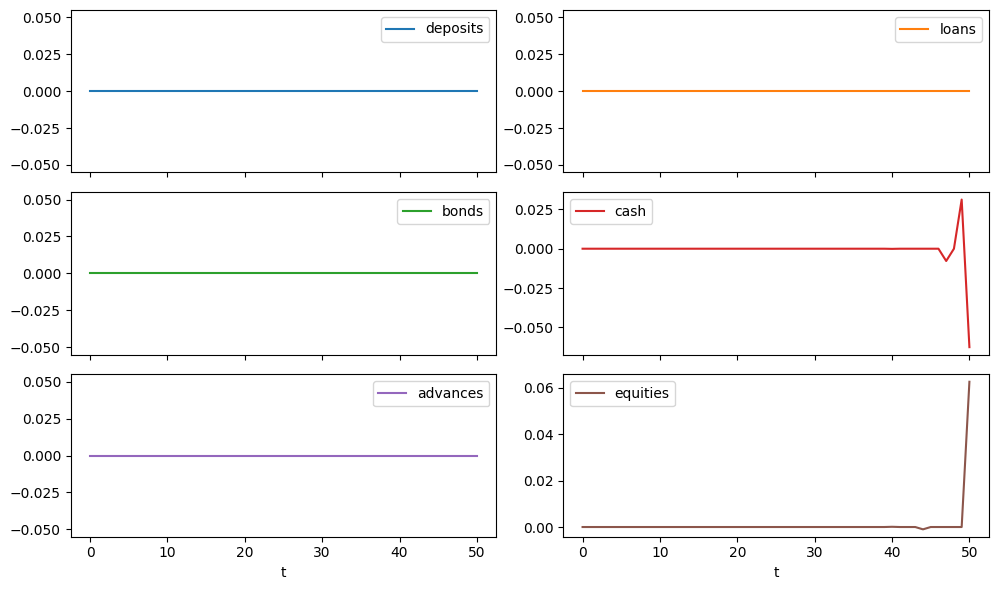

In [13]:
plot_stocks_consistency(stock_data)

## Matrice des flux

### Methodes de creation des matrices des flux

Nous utiliserons 3 fonctions:

* `create_transaction_data` pour la creation des donnees sur les transactions
* `create_change_data` pour la creation des donnees sur les variations de stocks
* `create_flows_matrix` pour la creation d'une matrice des stocks a une periode t
* `plot_flows_consistency` pour la visualisation de la coherence horizontale des flux
* `plot_vertical_consistency` pour la visualisation de la coherence verticale des flux



In [14]:
index_names = ["t", "obj_type"]
stock_names = list(FINANCIAL_ASSETS)
stock_data = data[stock_names + index_names].groupby(index_names).sum()
stock_data.tail(10)

deposits  loans  bonds          cash  advances      equities
t  obj_type                                                                 
48 Government        0.0    0.0    0.0 -3.840000e+02       0.0  0.000000e+00
   Household         0.0    0.0    0.0 -1.351080e+14       0.0  1.351080e+14
49 CentralBank       0.0    0.0    0.0  0.000000e+00       0.0  0.000000e+00
   Firm              0.0    0.0    0.0  2.702160e+14       0.0 -2.702160e+14
   Government        0.0    0.0    0.0 -3.920000e+02       0.0  0.000000e+00
   Household         0.0    0.0    0.0 -2.702160e+14       0.0  2.702160e+14
50 CentralBank       0.0    0.0    0.0  0.000000e+00       0.0  0.000000e+00
   Firm              0.0    0.0    0.0  5.404320e+14       0.0 -5.404320e+14
   Government        0.0    0.0    0.0 -4.000000e+02       0.0  0.000000e+00
   Household         0.0    0.0    0.0 -5.404320e+14       0.0  5.404320e+14

In [15]:
def create_transaction_data(raw_data):
    index_names = ["t", "obj_type"]
    flow_names = list(TRANSACTIONS)
    final_data = raw_data[flow_names + index_names].groupby(index_names).sum()
    return final_data

In [16]:
def create_change_data(raw_data):
    index_names = ["t", "obj_type"]
    flow_names = [f"delta_{name}" for name in FINANCIAL_ASSETS]
    final_data = raw_data[flow_names + index_names].groupby(index_names).sum()
    return final_data

In [17]:
def create_flows_matrix(transaction_data, change_data, t):
    sector_names = ["Household", "Firm", "Bank", "Government", "CentralBank"]
    transaction_matrix = transaction_data.loc[t].transpose()  
    change_matrix = change_data.loc[t].transpose()
    matrix = pd.concat([transaction_matrix, change_matrix])
    matrix = matrix.reindex(sector_names, axis=1, fill_value=0)  
    matrix.loc[:, "Total"] = matrix.sum(axis=1) 
    matrix.loc['Total', :] = matrix.sum(axis=0)
    matrix = matrix.round(4)
    matrix.columns.name = ""
    matrix.index.name = ""
    return matrix

In [18]:
def plot_flows_consistency(transaction_data, change_data):
    flows_data = pd.concat([transaction_data, change_data], axis=1)
    var_num = flows_data.shape[1]
    col_num = 3
    row_num = var_num // col_num + var_num % col_num
    figsize = col_num * 5, row_num * 2
    consistency = flows_data.groupby("t").sum().round(4)
    consistency.plot(subplots=True, layout=(row_num, col_num), figsize=figsize)
    plt.tight_layout()
    plt.show()

### Presentation des flux initiaux et finaux

In [19]:
transaction_data = create_transaction_data(data)
transaction_data.head(10)

consumption  wages  public_transfers  taxes  dep_interests  \
t obj_type                                                                  
0 CentralBank          0.0    0.0               0.0    0.0            0.0   
  Government           0.0    0.0               0.0    0.0            0.0   
  Household            0.0    0.0               0.0    0.0            0.0   
1 CentralBank          0.0    0.0               0.0    0.0            0.0   
  Government           0.0    0.0              -8.0    0.0            0.0   
  Household            0.0    0.0               8.0    0.0            0.0   
2 CentralBank          0.0    0.0               0.0    0.0            0.0   
  Firm                 0.0    0.0               0.0    0.0            0.0   
  Government           0.0    0.0              -8.0    0.0            0.0   
  Household            0.0    0.0               8.0    0.0            0.0   

               loan_interests  loan_defaults  bond_interests  cash_interests  \
t obj_type                                                                     
0 CentralBank             0.0            0.0             0.0             0.0   
  Government              0.0            0.0             0.0             0.0   
  Household               0.0            0.0             0.0             0.0   
1 CentralBank             0.0            0.0             0.0             0.0   
  Government              0.0            0.0             0.0             0.0   
  Household               0.0            0.0             0.0             0.0   
2 CentralBank             0.0            0.0             0.0             0.0   
  Firm                    0.0            0.0             0.0             0.0   
  Government              0.0            0.0             0.0             0.0   
  Household               0.0            0.0             0.0             0.0   

               adv_interests  dividends  profit_transfers  
t obj_type                                                 
0 CentralBank            0.0        0.0               0.0  
  Government             0.0        0.0               0.0  
  Household              0.0        0.0               0.0  
1 CentralBank            0.0        0.0               0.0  
  Government             0.0        0.0               0.0  
  Household              0.0        0.0               0.0  
2 CentralBank            0.0        0.0               0.0  
  Firm                   0.0        0.0               0.0  
  Government             0.0        0.0               0.0  
  Household              0.0        0.0               0.0

In [20]:
change_data = create_change_data(data)
change_data.head(10)

delta_deposits  delta_loans  delta_bonds  delta_cash  \
t obj_type                                                            
0 CentralBank             0.0          0.0          0.0        0.00   
  Government              0.0          0.0          0.0        0.00   
  Household               0.0          0.0          0.0        0.00   
1 CentralBank             0.0          0.0          0.0        0.00   
  Government              0.0          0.0          0.0        8.00   
  Household               0.0          0.0          0.0       -8.00   
2 CentralBank             0.0          0.0          0.0        0.00   
  Firm                    0.0          0.0          0.0      -10.24   
  Government              0.0          0.0          0.0        8.00   
  Household               0.0          0.0          0.0        2.24   

               delta_advances  delta_equities  
t obj_type                                     
0 CentralBank             0.0            0.00  
  Government              0.0            0.00  
  Household               0.0            0.00  
1 CentralBank             0.0            0.00  
  Government              0.0            0.00  
  Household               0.0            0.00  
2 CentralBank             0.0            0.00  
  Firm                    0.0           10.24  
  Government              0.0            0.00  
  Household               0.0          -10.24

In [21]:
print("Matrice initial des flux")
create_flows_matrix(transaction_data, change_data, 0)

Matrice initial des flux


,Household,Firm,Bank,Government,CentralBank,Total
,,,,,,
consumption,0.0,0.0,0.0,0.0,0.0,0.0
wages,0.0,0.0,0.0,0.0,0.0,0.0
public_transfers,0.0,0.0,0.0,0.0,0.0,0.0
taxes,0.0,0.0,0.0,0.0,0.0,0.0
dep_interests,0.0,0.0,0.0,0.0,0.0,0.0
loan_interests,0.0,0.0,0.0,0.0,0.0,0.0
loan_defaults,0.0,0.0,0.0,0.0,0.0,0.0
bond_interests,0.0,0.0,0.0,0.0,0.0,0.0
cash_interests,0.0,0.0,0.0,0.0,0.0,0.0


In [22]:
print("Matrice final des flux")
create_flows_matrix(transaction_data, change_data, params["steps"])

Matrice final des flux


,Household,Firm,Bank,Government,CentralBank,Total
,,,,,,
consumption,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0000
wages,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0000
public_transfers,8.000000e+00,0.000000e+00,0.0,-8.0,0.0,-0.0000
taxes,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0000
dep_interests,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0000
loan_interests,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0000
loan_defaults,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0000
bond_interests,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0000
cash_interests,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0000


### Analyse de la coherence des flux

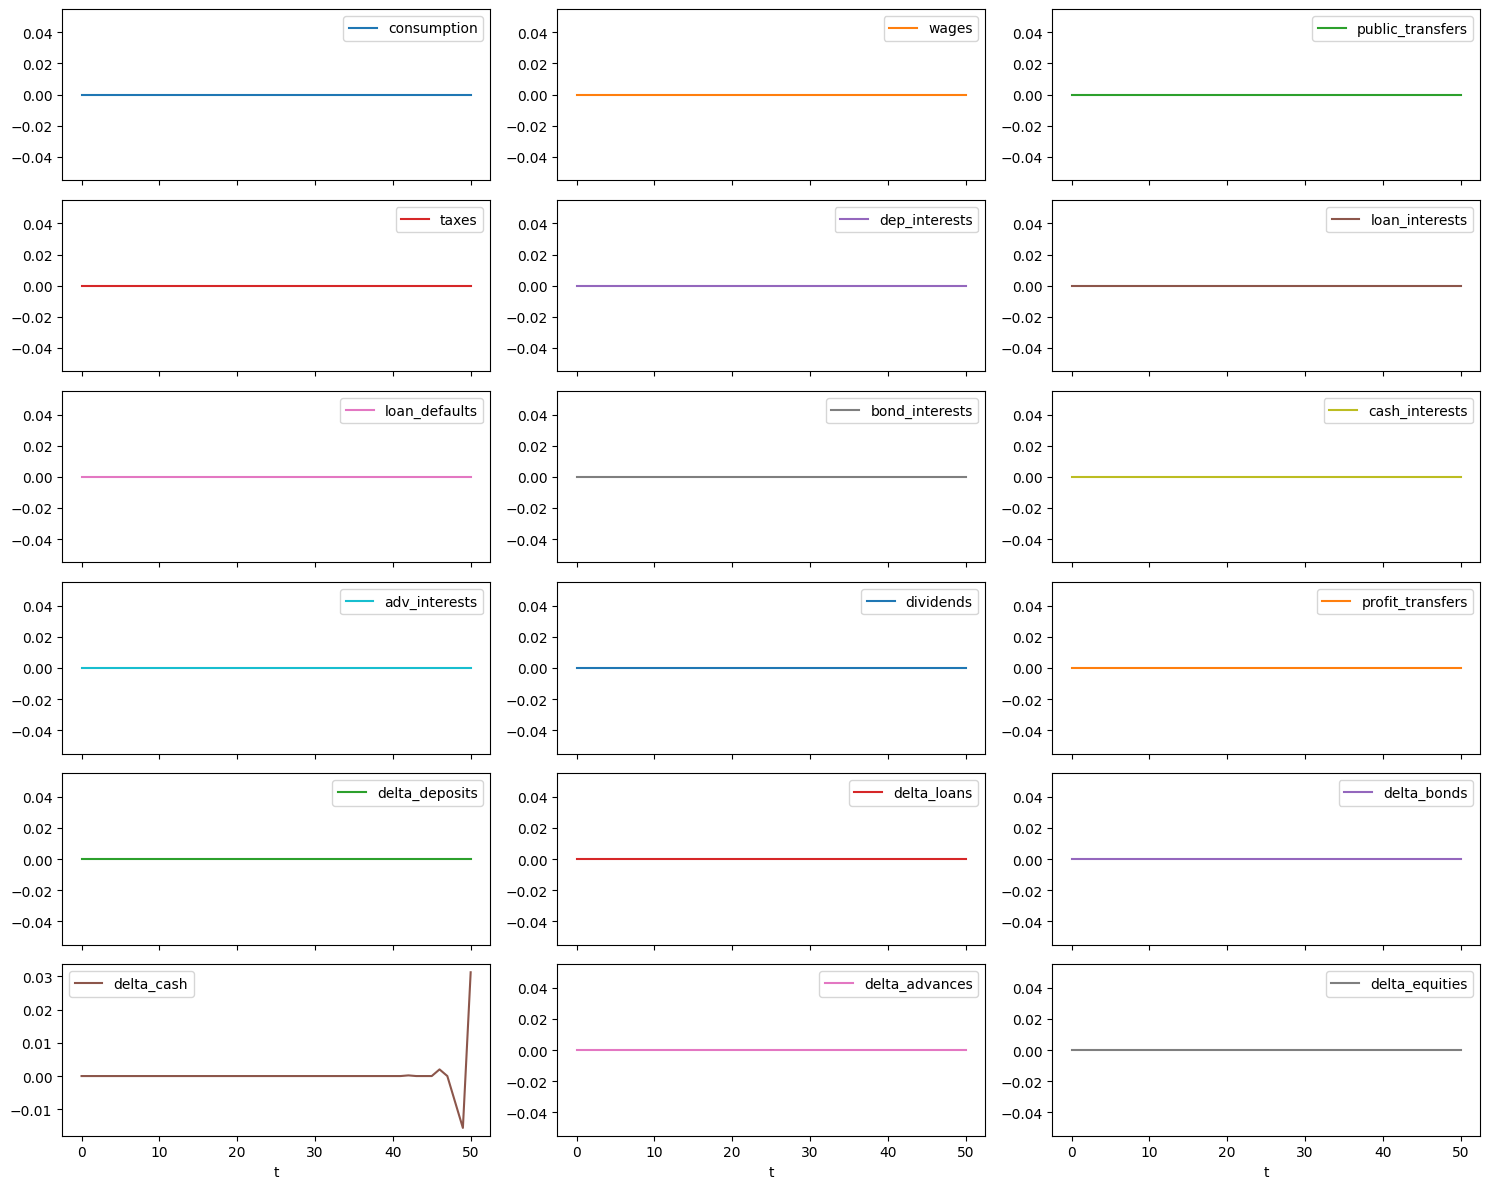

In [23]:
plot_flows_consistency(transaction_data, change_data)

In [24]:
print("Matrice des flux (premiere erreur sur les taxes)")
matrix = None
for t in range(params["steps"]):
    matrix = create_flows_matrix(transaction_data, change_data, t)
    total = matrix.loc["taxes", "Total"]
    if abs(total) >= 0.1:
        print("-> Periode", t)
        break
matrix

Matrice des flux (premiere erreur sur les taxes)


,Household,Firm,Bank,Government,CentralBank,Total
,,,,,,
consumption,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0000
wages,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0000
public_transfers,8.000000e+00,0.000000e+00,0.0,-8.0,0.0,-0.0000
taxes,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0000
dep_interests,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0000
loan_interests,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0000
loan_defaults,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0000
bond_interests,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0000
cash_interests,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0000
